# Can the Calendar Predict Rain in Seattle?

**How well can we predict rain using the **time of year alone**, and how much does prediction improve when we also use temperature and wind?



In [2]:
%pip install jinja2
import warnings
from pathlib import Path
import inspect

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report, recall_score
)
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
pd.set_option('display.max_columns', 50)

locations = [
    Path('seattle-weather.csv'),
    Path.home() / 'Downloads' / 'seattle-weather.csv',
    Path('/Users/noemigaggiotti/Downloads/seattle-weather.csv'),
    Path('/content/seattle-weather.csv')   
]
csv_path = next((p for p in locations if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        'Please place seattle-weather.csv in the notebook folder, '
        'or upload it to Colab and run again.'
    )

weather = pd.read_csv(csv_path)
required = {'date', 'weather', 'temp_max', 'temp_min', 'wind'}
missing_columns = required - set(weather.columns)
if missing_columns:
    raise ValueError(f'Missing expected columns: {missing_columns}')

print('Loaded from:', csv_path)
print('Dataset shape:', weather.shape)
print('Columns:', list(weather.columns))
print('\nSample rows:')
display(weather.head())
print('\nColumn information:')
weather.info()
print('\nSummary statistics:')
display(weather.describe(include='all'))
print('\nMissing values in raw data:')
print(weather.isna().sum())
print('Duplicate rows:', weather.duplicated().sum())
print('\nOriginal weather categories:')
print(weather['weather'].value_counts(dropna=False))


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Loaded from: seattle-weather.csv
Dataset shape: (1461, 6)
Columns: ['date', 'precipitation', 'temp_max', 'temp_min', 'wind', 'weather']

Sample rows:


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   str    
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   str    
dtypes: float64(4), str(2)
memory usage: 68.6 KB

Summary statistics:


,date,precipitation,temp_max,temp_min,wind,weather
count,1461,1461.000000,1461.000000,1461.000000,1461.000000,1461
unique,1461,NaN,NaN,NaN,NaN,5
top,2012-01-01,NaN,NaN,NaN,NaN,rain
freq,1,NaN,NaN,NaN,NaN,641
mean,NaN,3.029432,16.439083,8.234771,3.241136,NaN
std,NaN,6.680194,7.349758,5.023004,1.437825,NaN
min,NaN,0.000000,-1.600000,-7.100000,0.400000,NaN
25%,NaN,0.000000,10.600000,4.400000,2.200000,NaN
50%,NaN,0.000000,15.600000,8.300000,3.000000,NaN
75%,NaN,2.800000,22.200000,12.200000,4.000000,NaN



Missing values in raw data:
date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64
Duplicate rows: 0

Original weather categories:
weather
rain       641
sun        640
fog        101
drizzle     53
snow        26
Name: count, dtype: int64


# Data cleaning and feature engineering



In [3]:
df = weather.copy().drop_duplicates()


df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['weather'] = df['weather'].astype('string').str.strip().str.lower()
df = df.dropna(subset=['date', 'weather']).copy()

df['rain'] = (df['weather'] == 'rain').astype(int)

for column in ['temp_max', 'temp_min', 'wind']:
    df[column] = pd.to_numeric(df[column], errors='coerce')

def add_date_features(frame):
    """Create seasonal predictors from a dataframe with a 'date' column."""
    frame = frame.copy()
    d = pd.to_datetime(frame['date'])
    frame['year'] = d.dt.year
    frame['month'] = d.dt.month
    frame['day_of_year'] = d.dt.dayofyear
    days_in_year = np.where(d.dt.is_leap_year, 366, 365)
    theta = 2 * np.pi * (frame['day_of_year'] - 1) / days_in_year
    frame['day_sin'] = np.sin(theta)
    frame['day_cos'] = np.cos(theta)
    frame['wet_season'] = frame['month'].isin([10, 11, 12, 1, 2, 3, 4]).astype(int)

    frame['season'] = np.select(
        [frame['month'].isin([12, 1, 2]),
         frame['month'].isin([3, 4, 5]),
         frame['month'].isin([6, 7, 8])],
        ['Winter', 'Spring', 'Summer'],
        default='Fall'
    )
    return frame

df = add_date_features(df).sort_values('date').reset_index(drop=True)

print('Cleaned dataset:', df.shape)
print('Years available:', sorted(df['year'].unique().tolist()))
print('Rain classes (0 = not rain, 1 = rain):')
print(df['rain'].value_counts().sort_index())
print('Rain rate: {:.1%}'.format(df['rain'].mean()))
print('\nMissing values after cleaning:')
print(df[['temp_max', 'temp_min', 'wind', 'rain']].isna().sum())
display(df[['date', 'month', 'season', 'day_of_year', 'day_sin', 'day_cos',
            'wet_season', 'rain']].head())

Cleaned dataset: (1461, 14)
Years available: [2012, 2013, 2014, 2015]
Rain classes (0 = not rain, 1 = rain):
rain
0    820
1    641
Name: count, dtype: int64
Rain rate: 43.9%

Missing values after cleaning:
temp_max    0
temp_min    0
wind        0
rain        0
dtype: int64


,date,month,season,day_of_year,day_sin,day_cos,wet_season,rain
0,2012-01-01,1,Winter,1,0.000000,1.000000,1,0
1,2012-01-02,1,Winter,2,0.017166,0.999853,1,1
2,2012-01-03,1,Winter,3,0.034328,0.999411,1,1
3,2012-01-04,1,Winter,4,0.051479,0.998674,1,1
4,2012-01-05,1,Winter,5,0.068615,0.997643,1,1


## Exploratory data analysis (EDA)

**Questions investigated:** What proportion of days are rainy? Which months and seasons are rainiest? Are rainy days different in temperature or wind? We use *rain frequency* (percentage of days marked rain), not amount of precipitation, because rain/not-rain is our outcome.

Rain by month:


,month,days,rainy_days,rain_rate
0,1,124,61,49.2%
1,2,113,75,66.4%
2,3,124,73,58.9%
3,4,120,61,50.8%
4,5,124,40,32.3%
5,6,120,42,35.0%
6,7,124,16,12.9%
7,8,124,24,19.4%
8,9,120,36,30.0%
9,10,124,62,50.0%


Rain by season:


,season,days,rain_rate
0,Fall,364,47.5%
1,Spring,368,47.3%
2,Summer,368,22.3%
3,Winter,361,58.7%


Numerical summaries grouped by rain outcome:


temp_max              temp_min               wind             
         mean median   std     mean median   std  mean median   std
rain                                                               
0       18.77   20.0  8.03     8.74   10.0  5.67  2.91    2.7  1.21
1       13.45   12.8  4.97     7.59    7.2  3.95  3.67    3.4  1.59

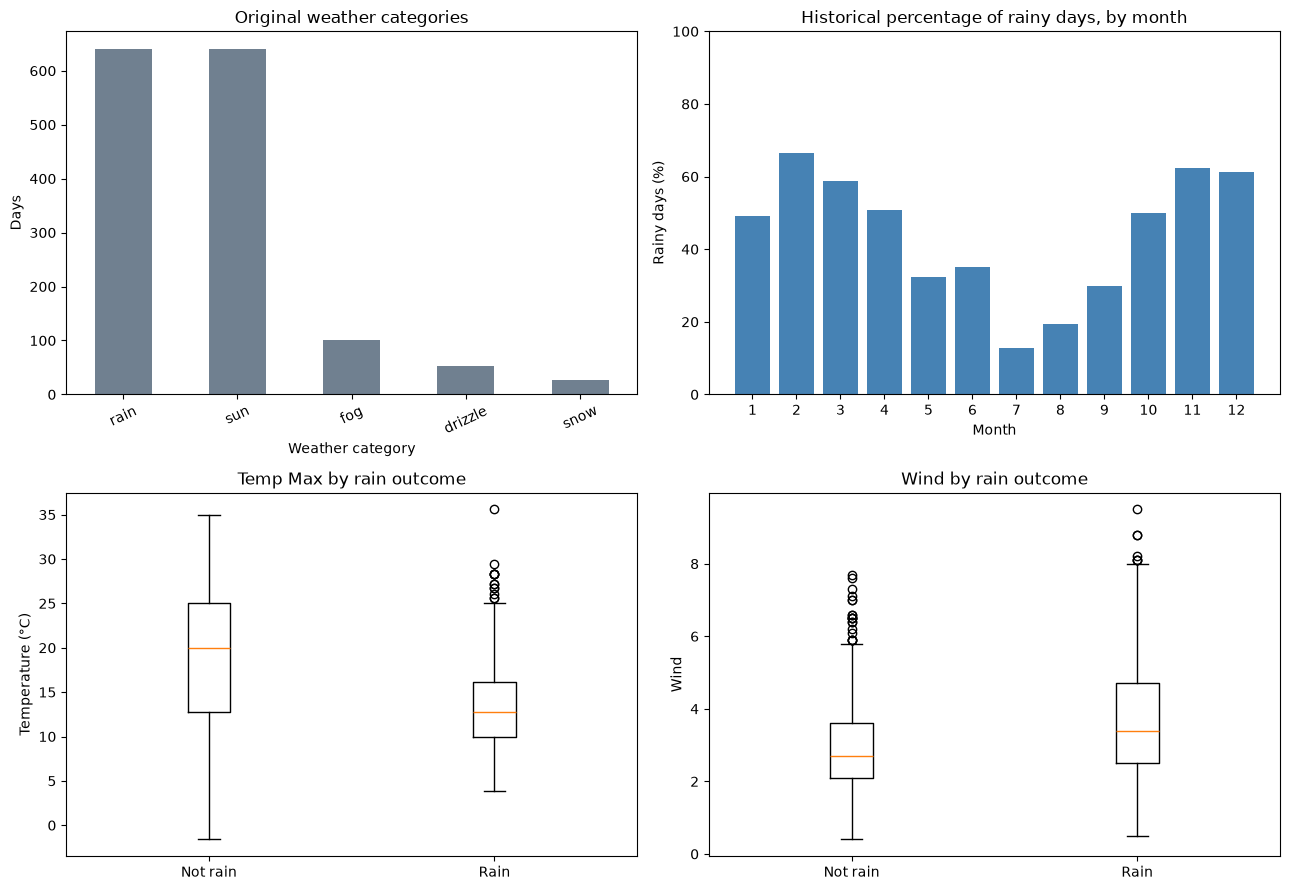

EDA interpretation: Month 2 has the highest rain frequency (66.4%), while month 7 has the lowest (12.9%) in this dataset.
These observations support using month and circular day-of-year features.


In [4]:

monthly_stats = (df.groupby('month', as_index=False)
                 .agg(days=('rain', 'size'), rainy_days=('rain', 'sum'),
                      rain_rate=('rain', 'mean')))
season_stats = (df.groupby('season', as_index=False)
                .agg(days=('rain', 'size'), rain_rate=('rain', 'mean')))

print('Rain by month:')
display(monthly_stats.style.format({'rain_rate': '{:.1%}'}))
print('Rain by season:')
display(season_stats.style.format({'rain_rate': '{:.1%}'}))
print('Numerical summaries grouped by rain outcome:')
display(df.groupby('rain')[['temp_max', 'temp_min', 'wind']].agg(['mean', 'median', 'std']).round(2))

#  EDA figures: label frequency, monthly rain probability, and temperatures/wind.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
df['weather'].value_counts().plot.bar(ax=axes[0, 0], color='slategray')
axes[0, 0].set_title('Original weather categories')
axes[0, 0].set_xlabel('Weather category')
axes[0, 0].set_ylabel('Days')
axes[0, 0].tick_params(axis='x', rotation=25)

axes[0, 1].bar(monthly_stats['month'], 100 * monthly_stats['rain_rate'], color='steelblue')
axes[0, 1].set_title('Historical percentage of rainy days, by month')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Rainy days (%)')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].set_ylim(0, 100)

for i, var in enumerate(['temp_max', 'wind']):
    ax = axes[1, i]
    vals = [df.loc[df['rain'] == cls, var].dropna() for cls in [0, 1]]
    ax.boxplot(vals, tick_labels=['Not rain', 'Rain'])
    ax.set_title(var.replace('_', ' ').title() + ' by rain outcome')
    ax.set_ylabel('Temperature (°C)' if var == 'temp_max' else 'Wind')

plt.tight_layout()
plt.show()

wettest = monthly_stats.loc[monthly_stats['rain_rate'].idxmax()]
driest = monthly_stats.loc[monthly_stats['rain_rate'].idxmin()]
print(f'EDA interpretation: Month {int(wettest.month)} has the highest rain frequency '
      f'({wettest.rain_rate:.1%}), while month {int(driest.month)} has the lowest '
      f'({driest.rain_rate:.1%}) in this dataset.')
print('These observations support using month and circular day-of-year features.')

# Use earlier years to predict a held-out future year

**Why a chronological split?** The goal is to learn seasonal patterns and predict rain in *later dates*. We use **2012–2014 for training** and **2015 for testing**. This is more realistic for a date-oriented question than randomly mixing all years into training and test sets.

The same held-out 2015 days are used for **all three models**, enabling a fair comparison. OOB scores are calculated using only the training data, and the test labels are not used to select hyperparameters.

In [5]:
if not ((df['year'] < 2015).any() and (df['year'] == 2015).any()):
    raise ValueError('Expected 2012–2014 training records and 2015 test records.')

train_mask = df['year'] < 2015
test_mask = df['year'] == 2015

y_train = df.loc[train_mask, 'rain'].copy()
y_test = df.loc[test_mask, 'rain'].copy()

# Engineered date variables are used directly in the models.
calendar_numeric = ['day_sin', 'day_cos', 'wet_season']
calendar_categories = ['month', 'season']
weather_numeric = ['temp_max', 'temp_min', 'wind']

calendar_features = calendar_numeric + calendar_categories
full_features = weather_numeric + calendar_features

X_calendar_train_raw = df.loc[train_mask, calendar_features].copy()
X_calendar_test_raw = df.loc[test_mask, calendar_features].copy()
X_full_train_raw = df.loc[train_mask, full_features].copy()
X_full_test_raw = df.loc[test_mask, full_features].copy()

print('Train years:', sorted(df.loc[train_mask, 'year'].unique()))
print('Test years:', sorted(df.loc[test_mask, 'year'].unique()))
print('Train rows:', len(y_train), 'Test rows:', len(y_test))
print('Train rain rate: {:.1%}; test rain rate: {:.1%}'.format(y_train.mean(), y_test.mean()))

Train years: [np.int32(2012), np.int32(2013), np.int32(2014)]
Test years: [np.int32(2015)]
Train rows: 1096 Test rows: 365
Train rain rate: 45.3%; test rain rate: 39.5%


## Preprocessing and encoding — fit on training data only

`month` and `season` are **categorical**, so one-hot encoding converts each category into binary indicators rather than implying that month 12 is 12 times month 1. The remaining predictors are numeric; numeric missing values are median-imputed, and the numeric features are standardized so the KNN base estimator can use meaningful distances. Trees do not need standardization, but applying one consistent preprocessing method makes the comparison easier.

**Important:** The imputer, scaler, and category encoder are fitted **only on 2012–2014**, not on the test year. No information from 2015 is used for feature preparation.

In [6]:

ohe_option = ('sparse_output' if 'sparse_output' in inspect.signature(OneHotEncoder).parameters
              else 'sparse')

def make_preprocessor(numeric_cols, categorical_cols):
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())
        ]), numeric_cols),
        ('categorical', OneHotEncoder(handle_unknown='ignore', **{ohe_option: False}),
         categorical_cols)
    ])

full_preprocessor = make_preprocessor(weather_numeric + calendar_numeric,
                                      calendar_categories)
calendar_preprocessor = make_preprocessor(calendar_numeric, calendar_categories)

X_train = full_preprocessor.fit_transform(X_full_train_raw)
X_test = full_preprocessor.transform(X_full_test_raw)
X_calendar_train = calendar_preprocessor.fit_transform(X_calendar_train_raw)
X_calendar_test = calendar_preprocessor.transform(X_calendar_test_raw)

print('Full model: original input columns:', len(full_features))
print('Full model: transformed input columns:', X_train.shape[1])
print('Calendar-only model: transformed columns:', X_calendar_train.shape[1])
print('Train/test feature matrices:', X_train.shape, X_test.shape)

assert not np.isnan(X_train).any() and not np.isnan(X_test).any()
assert not np.isnan(X_calendar_train).any() and not np.isnan(X_calendar_test).any()
print('Verified: no missing values remain in the model matrices.')

Full model: original input columns: 8
Full model: transformed input columns: 22
Calendar-only model: transformed columns: 19
Train/test feature matrices: (1096, 22) (365, 22)
Verified: no missing values remain in the model matrices.


# BaggingClassifier: grid search using OOB accuracy

**Model selection plan:** We compare two different **base estimators** (a decision tree and K-nearest neighbors) using different `n_estimators`, `max_samples`, and `max_features`. For *every combination*, `bootstrap=True` and `oob_score=True` are enabled. 

**OOB score** estimates accuracy using observations that an individual bootstrap estimator did not include in its training sample. We choose the **highest OOB score on the training years**; we do **not** inspect the held-out 2015 results while choo

In [7]:

def make_bagging(base_estimator, **kwargs):
    param = ('estimator' if 'estimator' in inspect.signature(BaggingClassifier).parameters
             else 'base_estimator')
    return BaggingClassifier(**{param: base_estimator}, **kwargs)

base_estimators = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    'KNN (7 neighbors)': KNeighborsClassifier(n_neighbors=7)
}

bagging_grid = {
    'n_estimators': [50, 100, 200],
    'max_samples': [0.70, 1.0],
    'max_features': [0.75, 1.0]
}

bagging_results = []
best_bagging = None
best_bagging_oob = -np.inf
best_bagging_parameters = None

for base_name, base in base_estimators.items():
    for params in ParameterGrid(bagging_grid):
        clf = make_bagging(
            clone(base),
            **params,
            bootstrap=True,
            oob_score=True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        clf.fit(X_train, y_train)
        score = clf.oob_score_
        bagging_results.append({'base_estimator': base_name, **params, 'oob_score': score})
        if score > best_bagging_oob:
            best_bagging_oob = score
            best_bagging = clf
            best_bagging_parameters = {'base_estimator': base_name, **params}

bagging_table = pd.DataFrame(bagging_results).sort_values('oob_score', ascending=False)
print('Bagging: combinations tested =', len(bagging_table))
display(bagging_table.head(10).style.format({'oob_score': '{:.4f}'}))
print('Best Bagging parameters:', best_bagging_parameters)
print(f'Best Bagging OOB accuracy: {best_bagging_oob:.4f}')

Bagging: combinations tested = 24


,base_estimator,max_features,max_samples,n_estimators,oob_score
10,Decision Tree,1.000000,1.000000,100,0.7774
8,Decision Tree,1.000000,0.700000,200,0.7765
3,Decision Tree,0.750000,1.000000,50,0.7755
4,Decision Tree,0.750000,1.000000,100,0.7755
6,Decision Tree,1.000000,0.700000,50,0.7755
0,Decision Tree,0.750000,0.700000,50,0.7746
1,Decision Tree,0.750000,0.700000,100,0.7746
7,Decision Tree,1.000000,0.700000,100,0.7746
5,Decision Tree,0.750000,1.000000,200,0.7728
11,Decision Tree,1.000000,1.000000,200,0.7728


Best Bagging parameters: {'base_estimator': 'Decision Tree', 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 100}
Best Bagging OOB accuracy: 0.7774


##RandomForestClassifier: grid search using OOB accuracy

We vary `n_estimators` (number of trees) and `max_features` (number of candidate features at each split). We keep `bootstrap=True`, `oob_score=True`, and `random_state=42` throughout. `min_samples_leaf=5` helps control overfitting on this small four-year dataset.


In [8]:
rf_grid = {
    'n_estimators': [50, 100, 200],
    'max_features': ['sqrt', 'log2', None]
}
rf_results = []
best_rf = None
best_rf_oob = -np.inf
best_rf_parameters = None

for params in ParameterGrid(rf_grid):
    clf = RandomForestClassifier(
        **params, min_samples_leaf=5,
        bootstrap=True, oob_score=True,
        random_state=RANDOM_STATE, n_jobs=-1
    )
    clf.fit(X_train, y_train)
    score = clf.oob_score_
    rf_results.append({**params, 'oob_score': score})
    if score > best_rf_oob:
        best_rf_oob = score
        best_rf = clf
        best_rf_parameters = dict(params)

rf_table = pd.DataFrame(rf_results).sort_values('oob_score', ascending=False)
print('Random Forest: combinations tested =', len(rf_table))
display(rf_table.style.format({'oob_score': '{:.4f}'}))
print('Best RF parameters:', best_rf_parameters)
print(f'Best Random Forest OOB accuracy: {best_rf_oob:.4f}')

Random Forest: combinations tested = 9


,max_features,n_estimators,oob_score
7,nan,100,0.7801
0,sqrt,50,0.7783
3,log2,50,0.7783
8,nan,200,0.7774
1,sqrt,100,0.7755
4,log2,100,0.7755
2,sqrt,200,0.7710
5,log2,200,0.7710
6,nan,50,0.7692


Best RF parameters: {'max_features': None, 'n_estimators': 100}
Best Random Forest OOB accuracy: 0.7801


##Creative experiment: Can dates **alone** predict rain?

This extra experiment deliberately **removes temperature and wind**. Its only predictors are engineered calendar features: month, season, wet-season indicator, and circular day-of-year features.

We repeat the Random Forest OOB parameter search using exactly the same training years, then compare its 2015 performance against the two models that have temperature and wind. This distinguishes predicting **typical seasonal rain probability** from predicting rain given *daily meteorological measurements*.

In [9]:
calendar_rf_results = []
best_calendar_rf = None
best_calendar_oob = -np.inf
best_calendar_params = None

for params in ParameterGrid(rf_grid):
    clf = RandomForestClassifier(
        **params, min_samples_leaf=12,
        bootstrap=True, oob_score=True,
        random_state=RANDOM_STATE, n_jobs=-1
    )
    clf.fit(X_calendar_train, y_train)
    score = clf.oob_score_
    calendar_rf_results.append({**params, 'oob_score': score})
    if score > best_calendar_oob:
        best_calendar_oob = score
        best_calendar_rf = clf
        best_calendar_params = dict(params)

calendar_table = pd.DataFrame(calendar_rf_results).sort_values('oob_score', ascending=False)
print('Calendar-only RF: combinations tested =', len(calendar_table))
display(calendar_table.style.format({'oob_score': '{:.4f}'}))
print('Best calendar-only settings:', best_calendar_params)
print(f'Best calendar-only RF OOB score: {best_calendar_oob:.4f}')

Calendar-only RF: combinations tested = 9


,max_features,n_estimators,oob_score
0,sqrt,50,0.6369
3,log2,50,0.6369
6,nan,50,0.6332
8,nan,200,0.6286
1,sqrt,100,0.6277
4,log2,100,0.6277
2,sqrt,200,0.6259
5,log2,200,0.6259
7,nan,100,0.6232


Best calendar-only settings: {'max_features': 'sqrt', 'n_estimators': 50}
Best calendar-only RF OOB score: 0.6369


##Final evaluation on the untouched 2015 test set


Bagging (weather + calendar)
              precision    recall  f1-score   support

    Not rain       0.84      0.75      0.79       221
        Rain       0.67      0.78      0.72       144

    accuracy                           0.76       365
   macro avg       0.76      0.77      0.76       365
weighted avg       0.78      0.76      0.77       365

Confusion matrix [[TN, FP], [FN, TP]]: [[166, 55], [31, 113]]

Random Forest (weather + calendar)
              precision    recall  f1-score   support

    Not rain       0.84      0.80      0.82       221
        Rain       0.71      0.76      0.74       144

    accuracy                           0.79       365
   macro avg       0.78      0.78      0.78       365
weighted avg       0.79      0.79      0.79       365

Confusion matrix [[TN, FP], [FN, TP]]: [[177, 44], [34, 110]]

Random Forest (calendar only)
              precision    recall  f1-score   support

    Not rain       0.68      0.59      0.63       221
        Rain    

,Model,OOB accuracy,Test accuracy,F1 (rain),Recall (not rain),Recall (rain),Predicted rain rate
0,Bagging (weather + calendar),0.777372,0.764384,0.724,0.751131,0.784722,0.460274
1,Random Forest (weather + calendar),0.780109,0.786301,0.738,0.800905,0.763889,0.421918
2,Random Forest (calendar only),0.636861,0.580822,0.517,0.588235,0.569444,0.473973


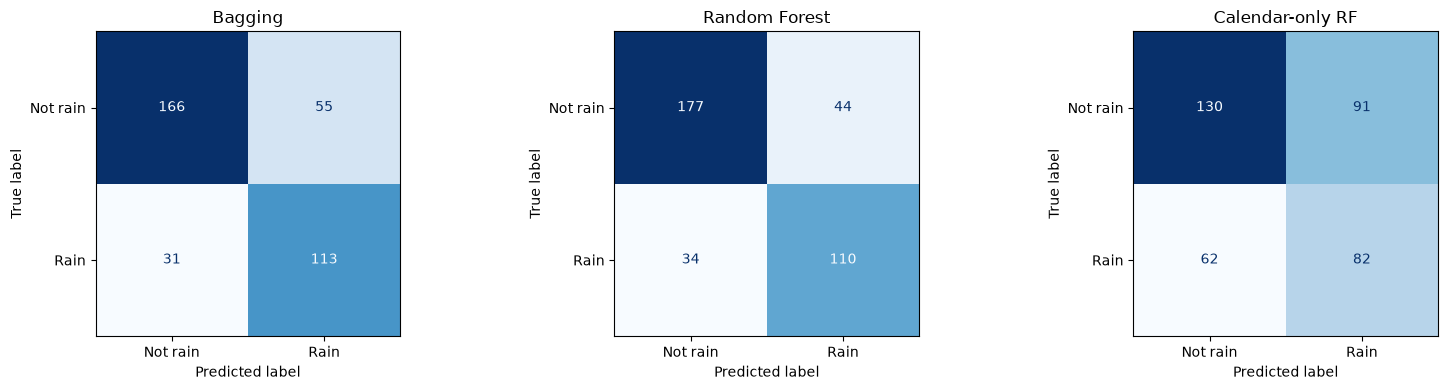

In [10]:
def evaluate_model(clf, X_holdout, title, oob_score):
    predictions = clf.predict(X_holdout)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    not_rain_recall = tn / (tn + fp) if (tn + fp) else np.nan
    rain_recall = tp / (tp + fn) if (tp + fn) else np.nan

    result = {
        'Model': title,
        'OOB accuracy': oob_score,
        'Test accuracy': accuracy_score(y_test, predictions),
        'F1 (rain)': f1_score(y_test, predictions, pos_label=1, zero_division=0),
        'Recall (not rain)': not_rain_recall,
        'Recall (rain)': rain_recall,
        'Predicted rain rate': np.mean(predictions == 1),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }
    print('\n' + title)
    print(classification_report(y_test, predictions,
                                labels=[0, 1], target_names=['Not rain', 'Rain'],
                                zero_division=0))
    print('Confusion matrix [[TN, FP], [FN, TP]]:', matrix.tolist())
    return result, predictions, matrix

bagging_metrics, bagging_predictions, bagging_cm = evaluate_model(
    best_bagging, X_test, 'Bagging (weather + calendar)', best_bagging_oob
)
rf_metrics, rf_predictions, rf_cm = evaluate_model(
    best_rf, X_test, 'Random Forest (weather + calendar)', best_rf_oob
)
calendar_metrics, calendar_predictions, calendar_cm = evaluate_model(
    best_calendar_rf, X_calendar_test, 'Random Forest (calendar only)', best_calendar_oob
)

results_df = pd.DataFrame([bagging_metrics, rf_metrics, calendar_metrics])
print('All models evaluated on exactly the same 2015 dates:')
display(results_df[['Model', 'OOB accuracy', 'Test accuracy', 'F1 (rain)',
                    'Recall (not rain)', 'Recall (rain)', 'Predicted rain rate']].style.format({
                        c: '{:.1%}' for c in [
                            'OOB accuracy', 'Test accuracy', 'Recall (not rain)',
                            'Recall (rain)', 'Predicted rain rate'
                        ]
                    }).format({'F1 (rain)': '{:.3f}'}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (title, matrix) in zip(axes, [
    ('Bagging', bagging_cm),
    ('Random Forest', rf_cm),
    ('Calendar-only RF', calendar_cm)
]):
    ConfusionMatrixDisplay(matrix, display_labels=['Not rain', 'Rain']).plot(
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

## Which model performed best? Did either model favor a class?



In [11]:
main_results = results_df.iloc[:2].copy()
best_test_idx = main_results['Test accuracy'].idxmax()
best_test_row = main_results.loc[best_test_idx]
print('Required comparison: BAGGING VS RANDOM FOREST')
print(f"Higher 2015 test accuracy: {best_test_row['Model']} "
      f"({best_test_row['Test accuracy']:.1%}).")

for row in results_df.to_dict('records'):
    favored = ('not-rain' if row['Recall (not rain)'] > row['Recall (rain)']
               else 'rain' if row['Recall (rain)'] > row['Recall (not rain)']
               else 'neither class')
    print(f"\n{row['Model']}:")
    print(f"  2015 accuracy = {row['Test accuracy']:.1%}, "
          f"F1 for rain = {row['F1 (rain)']:.3f}.")
    print(f"  Actual rainy days missed (false negatives): {row['FN']}; "
          f"non-rainy days wrongly called rainy (false positives): {row['FP']}.")
    print(f"  Recall: not-rain = {row['Recall (not rain)']:.1%}, "
          f"rain = {row['Recall (rain)']:.1%}; higher recall for {favored}.")

weather_winner = main_results.loc[main_results['Test accuracy'].idxmax()]
print('\nCREATIVE RESEARCH QUESTION')
print(f"Calendar-only RF accuracy: {calendar_metrics['Test accuracy']:.1%} ")
print(f"Best weather-informed model accuracy: {weather_winner['Test accuracy']:.1%} ")
print('The difference indicates how much test-set accuracy changes when daily '
      'temperature and wind are available in addition to calendar information.')

Required comparison: BAGGING VS RANDOM FOREST
Higher 2015 test accuracy: Random Forest (weather + calendar) (78.6%).

Bagging (weather + calendar):
  2015 accuracy = 76.4%, F1 for rain = 0.724.
  Actual rainy days missed (false negatives): 31; non-rainy days wrongly called rainy (false positives): 55.
  Recall: not-rain = 75.1%, rain = 78.5%; higher recall for rain.

Random Forest (weather + calendar):
  2015 accuracy = 78.6%, F1 for rain = 0.738.
  Actual rainy days missed (false negatives): 34; non-rainy days wrongly called rainy (false positives): 44.
  Recall: not-rain = 80.1%, rain = 76.4%; higher recall for not-rain.

Random Forest (calendar only):
  2015 accuracy = 58.1%, F1 for rain = 0.517.
  Actual rainy days missed (false negatives): 62; non-rainy days wrongly called rainy (false positives): 91.
  Recall: not-rain = 58.8%, rain = 56.9%; higher recall for not-rain.

CREATIVE RESEARCH QUESTION
Calendar-only RF accuracy: 58.1% 
Best weather-informed model accuracy: 78.6% 
The d

 Estimate rainy-day probability for **specific calendar dates**

A calendar-only classifier can accept a date in an arbitrary year because its predictors come **only from that date's calendar position**. We test January 15, April 15, July 15, October 15, and December 15.

Seasonal rain estimates (NOT literal forecasts for 2027):


,Calendar date,Estimated probability of rain
0,January 15,6.8%
1,April 15,65.8%
2,July 15,23.8%
3,October 15,53.9%
4,December 15,48.0%


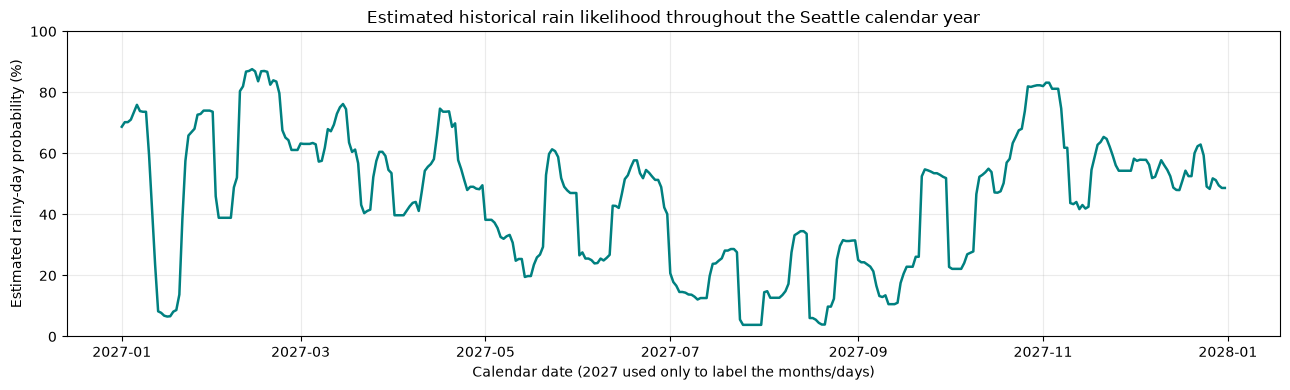

Highest date-only estimate in graph: February 13 (87.6%)
Lowest date-only estimate in graph: July 25 (3.8%)


In [12]:
example_dates = pd.to_datetime([
    '2027-01-15', '2027-04-15', '2027-07-15',
    '2027-10-15', '2027-12-15'
])
example_df = add_date_features(pd.DataFrame({'date': example_dates}))
example_X = calendar_preprocessor.transform(example_df[calendar_features])

# Explicitly locate class 1 so the code never assumes probability-column order.
rain_column = np.where(best_calendar_rf.classes_ == 1)[0][0]
example_probabilities = best_calendar_rf.predict_proba(example_X)[:, rain_column]

specific_dates = pd.DataFrame({
    'Calendar date': example_dates.strftime('%B %d'),
    'Estimated probability of rain': example_probabilities
})
print('Seasonal rain estimates (NOT literal forecasts for 2027):')
display(specific_dates.style.format({'Estimated probability of rain': '{:.1%}'}))

# Make a complete rain-likelihood calendar for each day of a non-leap year.
all_dates = pd.date_range('2027-01-01', '2027-12-31', freq='D')
year_df = add_date_features(pd.DataFrame({'date': all_dates}))
year_X = calendar_preprocessor.transform(year_df[calendar_features])
seasonal_probabilities = best_calendar_rf.predict_proba(year_X)[:, rain_column]

plt.figure(figsize=(13, 4))
plt.plot(all_dates, 100 * seasonal_probabilities, color='teal', linewidth=1.8)
plt.title('Estimated historical rain likelihood throughout the Seattle calendar year')
plt.ylabel('Estimated rainy-day probability (%)')
plt.xlabel('Calendar date (2027 used only to label the months/days)')
plt.ylim(0, 100)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

max_i = np.argmax(seasonal_probabilities)
min_i = np.argmin(seasonal_probabilities)
print('Highest date-only estimate in graph:',
      all_dates[max_i].strftime('%B %d'), f'({seasonal_probabilities[max_i]:.1%})')
print('Lowest date-only estimate in graph:',
      all_dates[min_i].strftime('%B %d'), f'({seasonal_probabilities[min_i]:.1%})')


In [14]:
print('FINAL PROJECT SUMMARY')
print('-' * 65)
print(f"Records analyzed: {len(df)} ({train_mask.sum()} train / {test_mask.sum()} test).")
print(f"Original rainy-day rate: {df['rain'].mean():.1%}.")
print('Engineered predictors: month, season, wet-season flag, circular day sine/cosine.')
print('The precipitation measurement was excluded to avoid target leakage.')
print(f"Bagging: best OOB = {best_bagging_oob:.1%}; "
      f"2015 accuracy = {bagging_metrics['Test accuracy']:.1%}; "
      f"F1 (rain) = {bagging_metrics['F1 (rain)']:.3f}.")
print('Bagging best settings:', best_bagging_parameters)
print(f"Random Forest: best OOB = {best_rf_oob:.1%}; "
      f"2015 accuracy = {rf_metrics['Test accuracy']:.1%}; "
      f"F1 (rain) = {rf_metrics['F1 (rain)']:.3f}.")
print('Random Forest best settings:', best_rf_parameters)
print(f"Calendar-only RF: best OOB = {best_calendar_oob:.1%}; "
      f"2015 accuracy = {calendar_metrics['Test accuracy']:.1%}; "
      f"F1 (rain) = {calendar_metrics['F1 (rain)']:.3f}.")
print('\nMain homework winner by TEST ACCURACY:', best_test_row['Model'])
print('Main homework winner by TEST F1:',
      main_results.loc[main_results['F1 (rain)'].idxmax(), 'Model'])
print('For class tendencies, refer to the per-class recall and confusion matrices.')
print('The 2027 calendar probabilities are illustrative, NOT real weather forecasts.')

FINAL PROJECT SUMMARY
-----------------------------------------------------------------
Records analyzed: 1461 (1096 train / 365 test).
Original rainy-day rate: 43.9%.
Engineered predictors: month, season, wet-season flag, circular day sine/cosine.
The precipitation measurement was excluded to avoid target leakage.
Bagging: best OOB = 77.7%; 2015 accuracy = 76.4%; F1 (rain) = 0.724.
Bagging best settings: {'base_estimator': 'Decision Tree', 'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 100}
Random Forest: best OOB = 78.0%; 2015 accuracy = 78.6%; F1 (rain) = 0.738.
Random Forest best settings: {'max_features': None, 'n_estimators': 100}
Calendar-only RF: best OOB = 63.7%; 2015 accuracy = 58.1%; F1 (rain) = 0.517.

Main homework winner by TEST ACCURACY: Random Forest (weather + calendar)
Main homework winner by TEST F1: Random Forest (weather + calendar)
For class tendencies, refer to the per-class recall and confusion matrices.
The 2027 calendar probabilities are illustrative

### Conclusion


This analysis demonstrates that while seasonal patterns provide some information about rainfall in Seattle, calendar features alone are not sufficient to reliably predict whether an individual day will be rainy. To optimize model performance, a manual grid search was performed using `ParameterGrid` to test different combinations of hyperparameters for the Bagging and Random Forest classifiers. Instead of traditional k-fold cross-validation with `GridSearchCV`, the models were evaluated using Out-of-Bag (OOB) accuracy. OOB scoring works by using observations that were left out of an individual model's bootstrap training sample to evaluate its predictions. Since bootstrap sampling selects observations randomly with replacement, some training observations are not selected for each estimator. Predictions from estimators that did not train on a particular observation are combined to estimate how accurately the ensemble performs on unseen data. This allows model performance to be evaluated during training without using the separate test dataset. The hyperparameter combination with the highest OOB accuracy was selected for each model.

The results showed that the Bagging classifier achieved an OOB accuracy of 77.7% and a test accuracy of 76.4%, while the Random Forest classifier achieved an OOB accuracy of 78.0% and a test accuracy of 78.6%. Random Forest performed best overall, with the highest test accuracy and F1 score for rainy days (0.738). It also demonstrated slightly better recall for non-rainy days (80.1%) than rainy days (76.4%). The calendar-only Random Forest achieved just 58.1% test accuracy, meaning that including temperature and wind improved accuracy by 20.5 percentage points. These findings suggest that although the time of year helps identify general seasonal rainfall patterns, daily weather conditions are more informative for predicting individual rainy days. However, the analysis is limited to four years of historical data, and the estimated probabilities for future calendar dates represent seasonal tendencies rather than actual weather forecasts.